1.
<p>Open a new notebook 'auto_subplots.ipynb', load 'auto_trips.csv' with `parse_dates=['trip_date']`, and build a 2x2 grid with `plt.subplots(2, 2, figsize=(12, 8))` showing daily total fare, distance vs fare, trips per area and a fare histogram, each with its own title. Call `tight_layout()` and save 'trip_grid.png'. Hint: Missed Session 10? Generate 600 trips with fare = 30 + 14 x distance plus noise and save 'auto_trips.csv' first.</p>
2.
<p>Create a dual-axis chart with `twinx()`: the left axis shows daily total fare as a solid line (`linewidth=2`, `marker='o'`), the right axis shows daily trip count as a dashed line (`linestyle='--'`, `marker='s'`), with coloured axis labels and one combined legend. Save it as 'fare_vs_trips_dual.png'. Hint: Join the handles from `get_legend_handles_labels()` of both axes.</p>
3.
<p>Plot the fare distribution of each area as box plots in one axes with `ax.boxplot`, using five lists built with a list comprehension and `df.loc`, and label the x ticks with the area names. Save it as 'fare_by_area_box.png'. Hint: Call `ax.set_xticklabels(areas)` after drawing. Constraint: Do not use `groupby` or Seaborn.</p>
4.
<p>Draw the daily total fare line again, mark the highest-fare day with `ax.annotate` and an arrow, write its fare with `ax.text`, and add the average daily total as a dashed `ax.axhline`. Assert the annotated date equals the `idxmax()` of the daily series and save 'fare_peak_annotated.png'. Run Restart & Run All and push to 's11_auto_subplots' in your GitHub repo 'ds_analysis_portfolio'.</p>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("auto_trips.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip().str.lower()

# Rename columns if needed
df.rename(columns={
    "date": "trip_date",
    "fare_inr": "fare",
    "distance_km": "distance",
    "tripid": "trip_id"
}, inplace=True)

# Convert date column
df["trip_date"] = pd.to_datetime(df["trip_date"])

print(df.head())
print(df.columns.tolist())

   trip_id  trip_date         area  distance  fare
0        1 2025-04-07  Navrangpura        10   189
1        2 2025-04-20        Paldi        13   214
2        3 2025-04-29        Paldi         8   143
3        4 2025-04-15        Paldi        14   234
4        5 2025-04-11    Satellite         2    45
['trip_id', 'trip_date', 'area', 'distance', 'fare']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6640\3096107294.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={


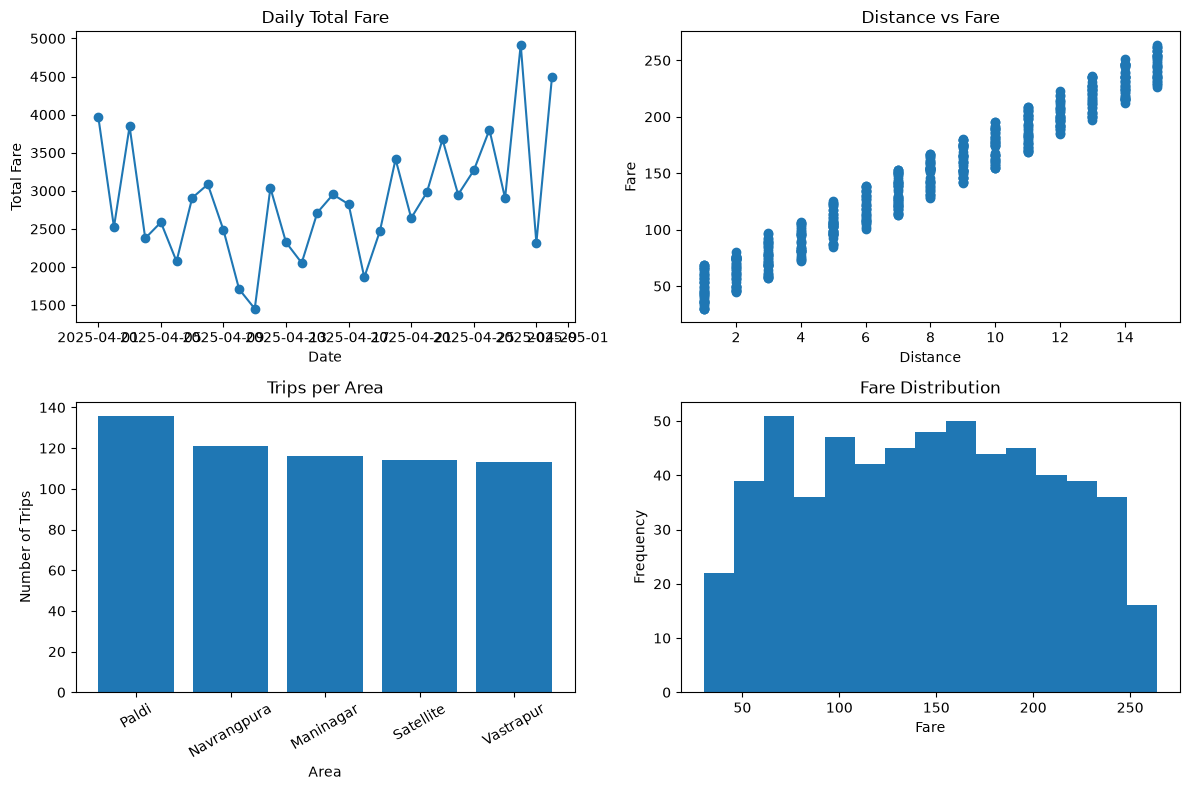

In [4]:
# Daily total fare
daily_fare = df.set_index("trip_date")["fare"].resample("D").sum()

# Create 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Daily total fare
axes[0, 0].plot(daily_fare, marker='o')
axes[0, 0].set_title("Daily Total Fare")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Total Fare")

# 2. Distance vs Fare
axes[0, 1].scatter(df["distance"], df["fare"])
axes[0, 1].set_title("Distance vs Fare")
axes[0, 1].set_xlabel("Distance")
axes[0, 1].set_ylabel("Fare")

# 3. Trips per area
area_counts = df["area"].value_counts()

axes[1, 0].bar(area_counts.index, area_counts.values)
axes[1, 0].set_title("Trips per Area")
axes[1, 0].set_xlabel("Area")
axes[1, 0].set_ylabel("Number of Trips")
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Fare histogram
axes[1, 1].hist(df["fare"], bins=15)
axes[1, 1].set_title("Fare Distribution")
axes[1, 1].set_xlabel("Fare")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()

plt.savefig("trip_grid.png")
plt.show()

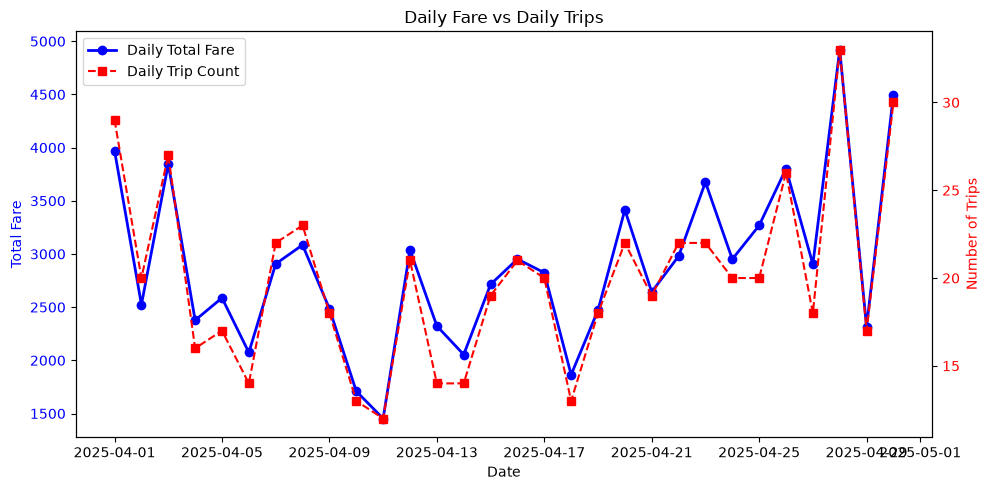

In [5]:
# Daily total fare
daily_fare = df.set_index("trip_date")["fare"].resample("D").sum()

# Daily trip count
daily_trips = df.set_index("trip_date")["trip_id"].resample("D").count()

fig, ax1 = plt.subplots(figsize=(10, 5))

# Left axis: Daily total fare
line1 = ax1.plot(
    daily_fare.index,
    daily_fare.values,
    color='blue',
    linewidth=2,
    marker='o',
    label="Daily Total Fare"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Total Fare", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Right axis: Daily trip count
ax2 = ax1.twinx()

line2 = ax2.plot(
    daily_trips.index,
    daily_trips.values,
    color='red',
    linestyle='--',
    marker='s',
    label="Daily Trip Count"
)

ax2.set_ylabel("Number of Trips", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Combined legend
lines = line1 + line2
labels = [line.get_label() for line in lines]

ax1.legend(lines, labels, loc="upper left")

plt.title("Daily Fare vs Daily Trips")
plt.tight_layout()

plt.savefig("fare_vs_trips_dual.png")
plt.show()

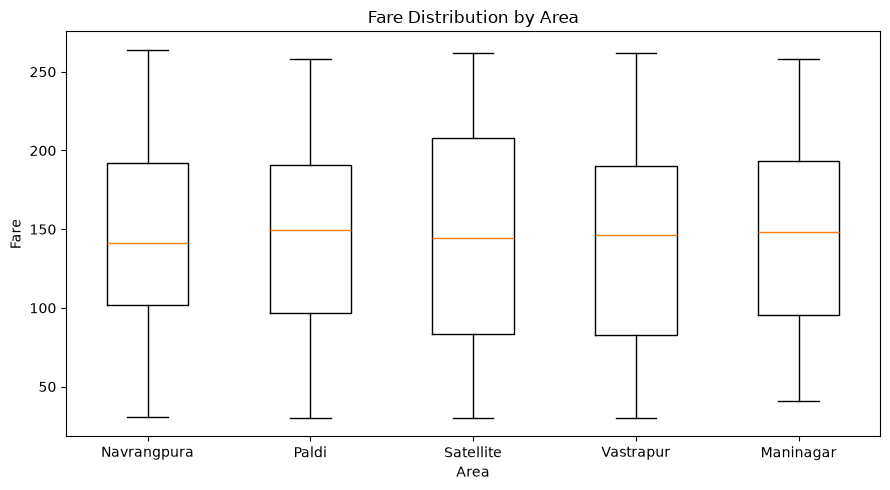

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

# Get area names
areas = df["area"].unique()

# Create five lists using list comprehension and df.loc
fare_data = [
    df.loc[df["area"] == area, "fare"].tolist()
    for area in areas
]

# Draw box plots
ax.boxplot(fare_data)

ax.set_xticklabels(areas)

ax.set_title("Fare Distribution by Area")
ax.set_xlabel("Area")
ax.set_ylabel("Fare")

plt.tight_layout()

plt.savefig("fare_by_area_box.png")
plt.show()